# 09 - Final Model

## Objective

Decisions from notebook 08: features `E1_core`, LightGBM with class weights.

Here we:
1. Train the final model on the training set.
2. Choose the threshold on the validation set (not 0.5 by default).
3. Evaluate **once** on the test set, and compare with the single rule `ratio_is_one`.
4. Explain the model (global importance and one example per transaction).
5. Save the model, the threshold and the feature list for the API.

## Imports and Data Loading

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from lightgbm import LGBMClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix)

sys.path.append('..')
from src.features import config
from src.data.splits import temporal_masks, TRAIN_END_STEP, VAL_END_STEP
from src.models.feature_sets import FEATURE_SETS, add_ratio_features

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
SEED = config.RANDOM_SEED
FEATURES = FEATURE_SETS['S1_core']   # same 8 features as E1_core in notebook 08
print(FEATURES)

['amount_log', 'oldbalanceOrg_log', 'oldbalanceDest_log', 'amount_to_balance_ratio', 'zero_old_balance_orig', 'ratio_gap_to_one', 'ratio_is_one', 'type_TRANSFER']


In [2]:
# Load the data and keep only CASH_OUT and TRANSFER (the only types with fraud).
table = add_ratio_features(pd.read_parquet(config.PROCESSED_PATH))
in_scope = (table['type_CASH_OUT'] + table['type_TRANSFER']) == 1
data = table[in_scope].reset_index(drop=True)
del table

# Time-based split: train <= step 500, validation 501-620, test after 620.
tr_mask, va_mask, te_mask = temporal_masks(data, TRAIN_END_STEP, VAL_END_STEP)
tr, va, te = data[tr_mask], data[va_mask], data[te_mask]
ytr, yva, yte = tr['isFraud'].to_numpy(), va['isFraud'].to_numpy(), te['isFraud'].to_numpy()
for name, y in [('train', ytr), ('validation', yva), ('test', yte)]:
    print(f'{name}: {len(y):,} rows, {y.sum():,} frauds ({y.mean() * 100:.2f}%)')

train: 2,645,779 rows, 5,561 frauds (0.21%)
validation: 86,155 rows, 1,286 frauds (1.49%)
test: 38,475 rows, 1,366 frauds (3.55%)


## 1. Train the final model

In [3]:
# Class weights are needed because fraud is rare.
model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                       class_weight='balanced', random_state=SEED, verbose=-1)
model.fit(tr[FEATURES], ytr)
s_va = model.predict_proba(va[FEATURES])[:, 1]
print('Validation PR-AUC:', round(average_precision_score(yva, s_va), 4),
      '| ROC-AUC:', round(roc_auc_score(yva, s_va), 4))

Validation PR-AUC: 1.0 | ROC-AUC: 1.0


## 2. Threshold on the validation set

We test thresholds from 0.05 to 0.95. The rule: the highest recall with at least 95% precision. If many thresholds give the same recall, we take the one in the middle of them, so the choice is not on the edge of a cliff.

In [4]:
# Precision, recall and alert counts for one threshold.
def metrics_at(y, scores, t):
    pred = scores >= t
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    return {'threshold': round(float(t), 2), 'precision': round(p, 4), 'recall': round(r, 4),
            'f1': round(2 * p * r / max(p + r, 1e-12), 4), 'caught': tp, 'missed': fn,
            'false_alerts': fp, 'alerts_per_10k': round((tp + fp) / len(y) * 10000, 1)}

# Try many thresholds on the validation set.
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
thr_table = pd.DataFrame([metrics_at(yva, s_va, t) for t in grid])
thr_table

,threshold,precision,recall,f1,caught,missed,false_alerts,alerts_per_10k
0,0.05,0.9961,1.0,0.9981,1286,0,5,149.8
1,0.10,0.9969,1.0,0.9984,1286,0,4,149.7
2,0.15,0.9977,1.0,0.9988,1286,0,3,149.6
3,0.20,0.9977,1.0,0.9988,1286,0,3,149.6
4,0.25,0.9977,1.0,0.9988,1286,0,3,149.6
5,0.30,0.9977,1.0,0.9988,1286,0,3,149.6
6,0.35,0.9977,1.0,0.9988,1286,0,3,149.6
7,0.40,0.9977,1.0,0.9988,1286,0,3,149.6
8,0.45,0.9977,1.0,0.9988,1286,0,3,149.6
9,0.50,0.9977,1.0,0.9988,1286,0,3,149.6


In [5]:
# Keep thresholds with precision >= 0.95, then the ones with the best recall.
# If several are equal, take the middle one.
ok = thr_table[thr_table['precision'] >= 0.95]
best_recall = ok['recall'].max()
cands = ok[ok['recall'] >= best_recall - 0.002]['threshold'].tolist()
THRESHOLD = sorted(cands)[len(cands) // 2] if cands else 0.5
print('Candidates:', cands, '-> chosen threshold:', THRESHOLD)
pd.DataFrame([metrics_at(yva, s_va, THRESHOLD)])

Candidates: [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95] -> chosen threshold: 0.5


,threshold,precision,recall,f1,caught,missed,false_alerts,alerts_per_10k
0,0.5,0.9977,1.0,0.9988,1286,0,3,149.6


**Observation:** The validation scores are almost all very close to 0 or to 1. Because of this, every threshold from 0.15 to 0.95 gives exactly the same result: all 1,286 frauds caught and 3 false alerts. Only below 0.15 do we get a few more false alerts. The threshold is not sensitive. We take 0.5, the middle of the flat zone.

## 3. Test set (used once)

The test period has a fraud rate of about 3.5%, higher than validation. PR-AUC depends on the fraud rate, so we also look at precision and recall at the fixed threshold. We compare with the single rule `ratio_is_one`.

In [6]:
# Test set: the model with the chosen threshold, and the single rule as a comparison.
s_te = model.predict_proba(te[FEATURES])[:, 1]
model_res = metrics_at(yte, s_te, THRESHOLD)
rule_res = metrics_at(yte, te['ratio_is_one'].to_numpy().astype(float), 0.5)
test_table = pd.DataFrame([{'who': 'LightGBM', **model_res}, {'who': 'Rule ratio_is_one', **rule_res}])
print('Test PR-AUC:', round(average_precision_score(yte, s_te), 4),
      '| ROC-AUC:', round(roc_auc_score(yte, s_te), 4),
      '| fraud rate:', round(yte.mean() * 100, 2), '%')
test_table

Test PR-AUC: 0.9997 | ROC-AUC: 1.0 | fraud rate: 3.55 %


,who,threshold,precision,recall,f1,caught,missed,false_alerts,alerts_per_10k
0,LightGBM,0.5,0.9971,0.9993,0.9982,1365,1,4,355.8
1,Rule ratio_is_one,0.5,1.0000,0.9619,0.9806,1314,52,0,341.5


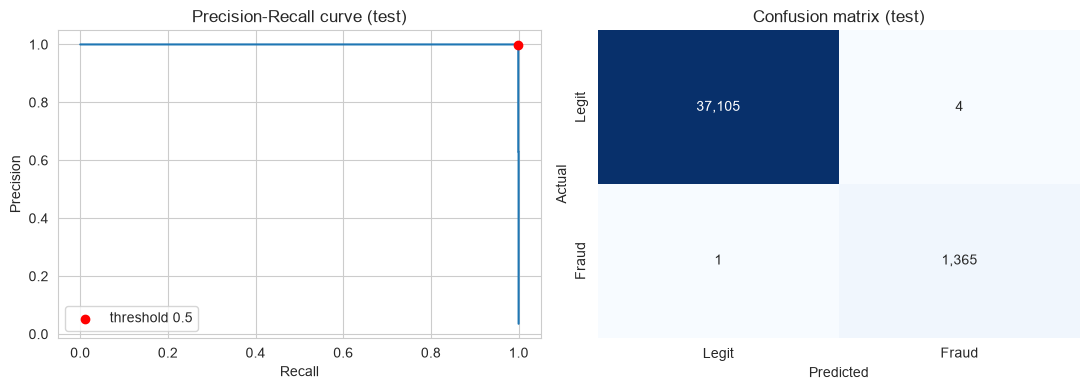

In [7]:
# Precision-recall curve and confusion matrix on the test set.
os.makedirs('../reports/figures', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

p, r, _ = precision_recall_curve(yte, s_te)
axes[0].plot(r, p)
axes[0].scatter([model_res['recall']], [model_res['precision']], color='red', zorder=3, label=f'threshold {THRESHOLD}')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision'); axes[0].set_title('Precision-Recall curve (test)')
axes[0].legend(loc='lower left')

cm = confusion_matrix(yte, s_te >= THRESHOLD)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual'); axes[1].set_title('Confusion matrix (test)')
plt.tight_layout()
plt.savefig('../reports/figures/final_test_results.png', dpi=120)
plt.show()

**Observation:** On the test period (fraud rate 3.55%, much higher than in training) the model keeps the same quality: PR-AUC 0.9997, 1,365 of 1,366 frauds caught and 4 false alerts (precision 0.997).

The rule `ratio_is_one` alone has no false alert but misses 52 frauds (recall 0.962). The model finds 51 more frauds than the rule for only 4 false alerts. So the model is better than the single rule, but the gain comes from a small group of frauds.

## 4. Explanations

LightGBM can return the contribution of each feature to each prediction (in log-odds, SHAP-style). A positive value pushes the transaction toward fraud.

**Global:** mean absolute contribution on the validation set.

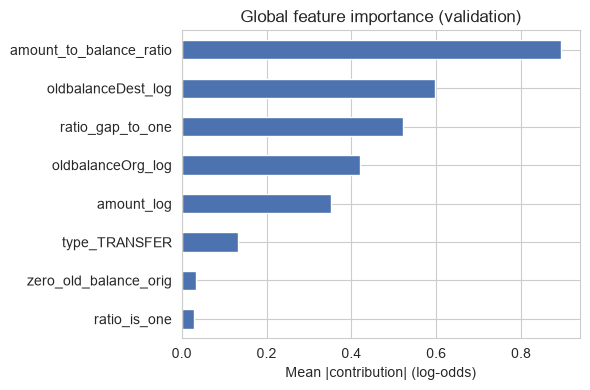

,mean_abs_contribution
amount_to_balance_ratio,0.8942
oldbalanceDest_log,0.5973
ratio_gap_to_one,0.5220
oldbalanceOrg_log,0.4202
amount_log,0.3508
type_TRANSFER,0.1337
zero_old_balance_orig,0.0325
ratio_is_one,0.0297


In [8]:
# pred_contrib gives one contribution per feature plus a base value (last column, removed here).
contrib_va = model.predict(va[FEATURES], pred_contrib=True)[:, :-1]
global_imp = pd.Series(np.abs(contrib_va).mean(axis=0), index=FEATURES).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 4))
global_imp[::-1].plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_xlabel('Mean |contribution| (log-odds)'); ax.set_title('Global feature importance (validation)')
plt.tight_layout()
plt.savefig('../reports/figures/final_feature_importance.png', dpi=120)
plt.show()
global_imp.round(4).to_frame('mean_abs_contribution')

**Local:** one detected fraud and one legit transaction with a high score (test set).

In [9]:
# Score and top contributions for one transaction.
def explain(df, i, top=4):
    row = df[FEATURES].iloc[[i]]
    score = model.predict_proba(row)[0, 1]
    contrib = pd.Series(model.predict(row, pred_contrib=True)[0][:-1], index=FEATURES)
    contrib = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:top]
    return round(float(score), 4), pd.DataFrame({'value': row.iloc[0][contrib.index], 'contribution': contrib.round(3)})

# One detected fraud, and the legit transaction that gets the highest score.
fraud_idx = np.flatnonzero((yte == 1) & (s_te >= THRESHOLD))[0]
legit_idx = np.flatnonzero(yte == 0)[np.argmax(s_te[yte == 0])]
for label, i in [('Detected fraud', fraud_idx), ('Legit with the highest score', legit_idx)]:
    sc, tab = explain(te, i)
    print(f'{label}: score {sc}')
    print(tab.to_string(), '\n')

Detected fraud: score 1.0
                        value  contribution
ratio_gap_to_one     0.000000        26.108
ratio_is_one         1.000000         1.835
oldbalanceDest_log   0.000000         0.548
oldbalanceOrg_log   12.762117        -0.294 

Legit with the highest score: score 0.9658
                             value  contribution
amount_log               11.468139         6.355
oldbalanceDest_log       13.060672         5.811
amount_to_balance_ratio  -1.000000         2.297
oldbalanceOrg_log         0.000000         1.046 



**Observation:**
- Global: the model mainly uses the amount-to-balance ratio and the destination balance. `ratio_gap_to_one`, `oldbalanceOrg_log` and `amount_log` come next. `ratio_is_one` is almost not used, because `ratio_gap_to_one` already gives the same information.
- Local, detected fraud: the amount is exactly the full balance (`ratio_gap_to_one` = 0), and this gives a very large push toward fraud.
- Local, legit transaction with a high score (0.97): a big TRANSFER from an account with a zero balance to a rich destination account. This looks like fraud for the model. It is the kind of false alert that remains.
- These are contributions of the model on this dataset. They show what the model uses, not what causes fraud.

## 5. Save the model

The API will load this file. It contains the model, the threshold and the feature list, so training and API use the same things.

In [10]:
# Save everything the API needs: model, threshold, feature list and the main results.
os.makedirs('../models', exist_ok=True)
artifact = {
    'model': model, 'threshold': THRESHOLD, 'features': FEATURES, 'version': '1.0',
    'description': 'LightGBM, class weights, CASH_OUT and TRANSFER only, trained on PaySim steps <= 500',
    'validation': metrics_at(yva, s_va, THRESHOLD), 'test': model_res,
}
joblib.dump(artifact, '../models/final_model.joblib')
print('Saved ../models/final_model.joblib')

Saved ../models/final_model.joblib


## 6. Conclusion and next step

**Results**
- Final model: LightGBM with class weights on 8 features. All the features come from one transaction.
- Threshold 0.5, chosen on validation. The result does not change between 0.15 and 0.95.
- Test: 1,365 of 1,366 frauds caught, 4 false alerts. The rule `ratio_is_one` alone catches 1,314 with 0 false alerts.


**Next step:** the API (`/predict`, `/predict/batch`), a simple web page, tests and a Dockerfile.